<a href="https://colab.research.google.com/github/AliAlaa22/amit_diploma/blob/main/Messy_Food_Waste_Prediction_Dataset_kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.linear_model import LinearRegression,Lasso,Ridge,SGDRegressor,LogisticRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error,f1_score
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from xgboost import XGBRegressor
import warnings
warnings.simplefilter("ignore")
df=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")

# Exploratory Data Analysis (EDA)

In [52]:
df

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt,51.549053
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT,44.156984
...,...,...,...,...,...,...,...,...,...,...,...,...
906,1044,2022-03-29,395,18,17.354199,45.138435,1,0,40.550668,Intermediate,GRAINS,50.369152
907,1045,2022-11-27,483,11,24.912137,59.485091,6,0,36.470276,intermediate,dairy,43.070121
908,1046,2023-04-12,243,11,28.870945,70.508404,2,0,19.767203,Intermediate,MeAt,29.632560
909,1048,2022-02-14,406,10,19.061638,55.286642,0,0,28.560361,EXPERT,MEAT,44.615759


In [53]:
df.info() ## 164 null value in staff_experience  column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB


In [54]:
df.describe()

,ID,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,food_waste_kg
count,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000
mean,528.327113,375.405049,11.900110,22.189280,60.761313,3.014270,0.085620,27.015691,44.842691
std,305.072794,502.812717,4.285153,8.922389,17.330821,2.009542,0.279956,12.774223,27.934366
min,0.000000,100.000000,5.000000,-10.372207,30.121111,0.000000,0.000000,5.008394,10.819048
25%,266.000000,211.000000,8.000000,15.684585,46.017835,1.000000,0.000000,16.091383,32.887912
50%,531.000000,306.000000,12.000000,22.115040,61.633960,3.000000,0.000000,26.854109,41.146930
75%,795.500000,407.000000,15.000000,28.804294,75.787910,5.000000,0.000000,38.149878,50.046681
max,1049.000000,4730.000000,19.000000,60.000000,89.982828,6.000000,1.000000,49.803703,274.328783


# Change Data Type

In [55]:
df.dtypes

,0
ID,int64
date,object
meals_served,int64
kitchen_staff,int64
temperature_C,float64
humidity_percent,float64
day_of_week,int64
special_event,int64
past_waste_kg,float64
staff_experience,object


In [56]:
df['waste_category'] = df['waste_category'].str.lower()# this function make all column word lower so no duplicate

In [57]:
df[["staff_experience","waste_category"]]=df[["staff_experience","waste_category"]].astype("category")
df["special_event"]=df["special_event"].astype("boolean")

In [58]:
df.dtypes

,0
ID,int64
date,object
meals_served,int64
kitchen_staff,int64
temperature_C,float64
humidity_percent,float64
day_of_week,int64
special_event,boolean
past_waste_kg,float64
staff_experience,category


# Data Preprocessing

In [59]:
#1-Handel null values in staff_experience  and its category column so we replace null values with mode or 0
df['staff_experience'].fillna(df['staff_experience'].mode()[0], inplace=True)
df.isnull().sum()

,0
ID,0
date,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
staff_experience,0


In [60]:
#2-Check Duplicated Values
df.duplicated().sum()

np.int64(0)

In [61]:
#Total Of Null Values
df.isnull().sum()

,0
ID,0
date,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
staff_experience,0


In [62]:
#Drop Column
df.drop(columns=["date","ID"],inplace=True)

# Data visualization

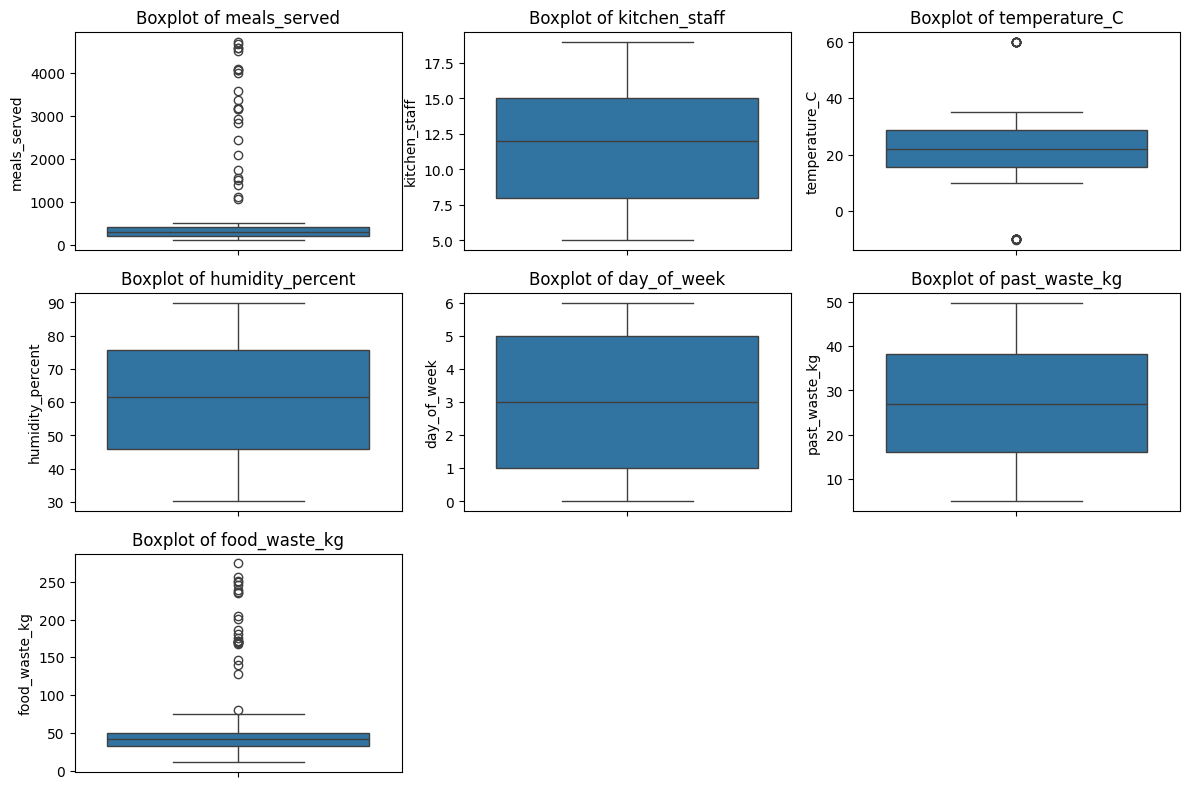

In [63]:
df_numeric = df.select_dtypes(include=['number'])
plt.figure(figsize=(12, 8))
for i, col in enumerate(df_numeric.columns, 1):
    plt.subplot(3, 3, i)  # Adjust grid layout if needed
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()


# Data Preprocessing

In [64]:
Q1=df["meals_served"].quantile(0.25)
Q3=df["meals_served"].quantile(0.75)
IQR=Q3-Q1
upper_limit_of_meals_served=Q3+(1.5*IQR)
lower_limit_of_meals_served=Q1-(1.5*IQR)

<Axes: ylabel='meals_served'>

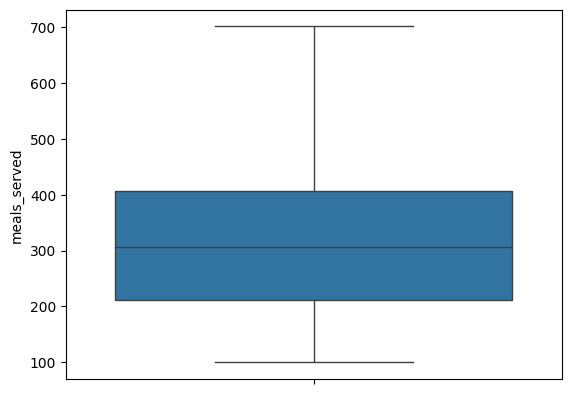

In [65]:
df.loc[(df["meals_served"]>upper_limit_of_meals_served),"meals_served"]=upper_limit_of_meals_served
df.loc[(df["meals_served"]<lower_limit_of_meals_served),"meals_served"]=lower_limit_of_meals_served
sns.boxplot(df["meals_served"])

In [66]:
Q1=df["food_waste_kg"].quantile(0.25)
Q3=df["food_waste_kg"].quantile(0.75)
IQR=Q3-Q1
upper_limit_of_food_waste_kg=Q3+(1.5*IQR)
lower_limit_of_food_waste_kg=Q1-(1.5*IQR)

<Axes: ylabel='food_waste_kg'>

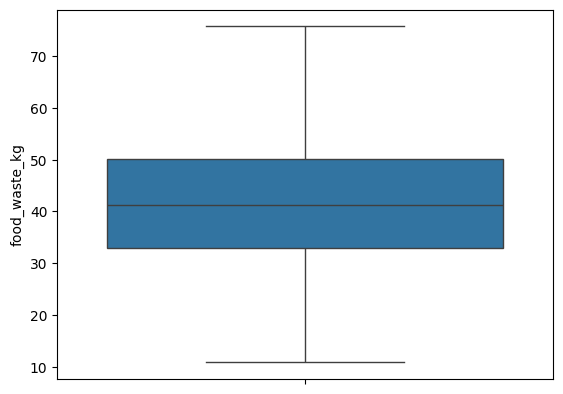

In [67]:
df.loc[(df["food_waste_kg"]>upper_limit_of_food_waste_kg),"food_waste_kg"]=upper_limit_of_food_waste_kg
df.loc[(df["food_waste_kg"]<lower_limit_of_food_waste_kg),"food_waste_kg"]=lower_limit_of_food_waste_kg
sns.boxplot(df["food_waste_kg"])

In [68]:
Q1=df["temperature_C"].quantile(0.25)
Q3=df["temperature_C"].quantile(0.75)
IQR=Q3-Q1
upper_limit_of_temperature_C=Q3+(1.5*IQR)
lower_limit_of_temperature_C=Q1-(1.5*IQR)

<Axes: ylabel='temperature_C'>

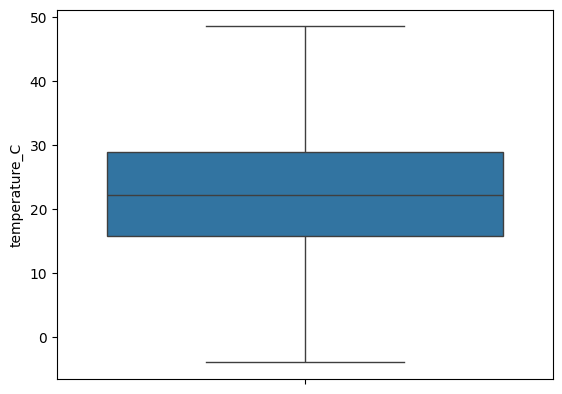

In [69]:
df.loc[(df["temperature_C"]>upper_limit_of_temperature_C),"temperature_C"]=upper_limit_of_temperature_C
df.loc[(df["temperature_C"]<lower_limit_of_temperature_C),"temperature_C"]=lower_limit_of_temperature_C
sns.boxplot(df["temperature_C"])

# Split Data

In [70]:
df=pd.get_dummies(df, columns=['staff_experience','waste_category'],drop_first=True,dtype=int)# here i make columns staff_experience,waste_category 0,1 for put in model
# df.drop(columns=['staff_experience',"waste_category"], inplace=True)

In [71]:
# pd.concat([df1,df])

In [72]:
df.isnull().sum()

,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
food_waste_kg,0
staff_experience_EXPERT,0
staff_experience_Intermediate,0


In [73]:
X=df.drop(["food_waste_kg"],axis=1)
y=(df["food_waste_kg"])

In [74]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [75]:
X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,test_size=0.2,random_state=42)

In [76]:
model=RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train,y_train)
y_pred_test=model.predict(X_test)
mean=mean_absolute_error(y_test,y_pred_test)
R2_score=r2_score(y_test,y_pred_test)
print(f'Mean: {mean:.2f}')
print(f'r2_score: {R2_score:.2f}')

Mean: 4.23
r2_score: 0.81


In [77]:
# # Train an XGBoost model
# xgb_model = XGBRegressor(n_estimators=100, random_state=42)
# xgb_model.fit(X_train, y_train)
# xgb_pred = xgb_model.predict(X_test)
# xgb_mae = mean_absolute_error(y_test, xgb_pred)
# xgb_r2score = r2_score(y_test, xgb_pred)
# print(f'Mean: {xgb_mae:.2f}')
# print(f'r2_score: {xgb_r2score:.2f}')

#  Test Data

In [78]:
id_subm=test["ID"]

In [79]:
test['waste_category'] = test['waste_category'].str.lower()# this function make all column word lower so no duplicate

In [80]:
test[["staff_experience","waste_category"]]=test[["staff_experience","waste_category"]].astype("category")
test["special_event"]=df["special_event"].astype("boolean")

In [81]:
#1-Handel null values in staff_experience  and its category column so we replace null values with mode or 0
test['staff_experience'].fillna(test['staff_experience'].mode()[0], inplace=True)
test.isnull().sum()

,0
ID,0
date,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
staff_experience,0


In [82]:
#2-Check Duplicated Values
test.duplicated().sum()

np.int64(0)

In [83]:
#Total Of Null Values
test.isnull().sum()

,0
ID,0
date,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
staff_experience,0


In [84]:
#Drop Column
test.drop(columns=["date","ID"],inplace=True)

In [85]:
Q1=test["meals_served"].quantile(0.25)
Q3=test["meals_served"].quantile(0.75)
IQR=Q3-Q1
upper_limit_of_meals_served=Q3+(1.5*IQR)
lower_limit_of_meals_served=Q1-(1.5*IQR)

<Axes: ylabel='meals_served'>

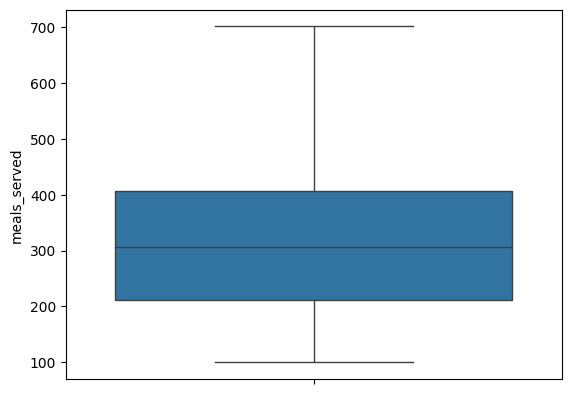

In [86]:
test.loc[(test["meals_served"]>upper_limit_of_meals_served),"meals_served"]=upper_limit_of_meals_served
test.loc[(test["meals_served"]<lower_limit_of_meals_served),"meals_served"]=lower_limit_of_meals_served
sns.boxplot(test["meals_served"])

In [87]:
Q1=test["temperature_C"].quantile(0.25)
Q3=test["temperature_C"].quantile(0.75)
IQR=Q3-Q1
upper_limit_of_temperature_C=Q3+(1.5*IQR)
lower_limit_of_temperature_C=Q1-(1.5*IQR)

<Axes: ylabel='temperature_C'>

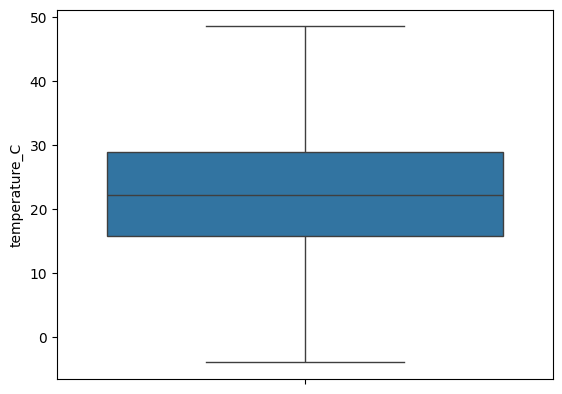

In [88]:
test.loc[(test["temperature_C"]>upper_limit_of_temperature_C),"temperature_C"]=upper_limit_of_temperature_C
test.loc[(test["temperature_C"]<lower_limit_of_temperature_C),"temperature_C"]=lower_limit_of_temperature_C
sns.boxplot(test["temperature_C"])

In [89]:
test=pd.get_dummies(test, columns=['staff_experience','waste_category'],drop_first=True,dtype=int)# here i make columns staff_experience,waste_category 0,1 for put in model
# df.drop(columns=['staff_experience',"waste_category"], inplace=True)

In [90]:
test_scaled=scaler.transform(test)
test_pred=model.predict(test_scaled)
submission=pd.DataFrame({
    "ID":id_subm,
    "food_waste_kg":test_pred
})

In [91]:
submission.to_csv("submission.csv",index=False)
print("Submission File Created Successfully!")
display(submission.head())

Submission File Created Successfully!


,ID,food_waste_kg
0,0,26.403178
1,1,49.743402
2,4,51.728276
3,5,46.798593
4,6,44.158423
